# Predicting smallholder maize yield in Kenya from farm practices and soil

This notebook uses the One Acre Fund Kenya farm survey (long rains, 2016 to 2020) and a 1 km soil grid built from iSDAsoil. The target is maize yield in kg per hectare, measured by crop cuts.

In [40]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [41]:
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
OUT = "outputs"                             
os.makedirs(OUT, exist_ok=True)
SOIL = ["soil_ph", "soil_carbon", "soil_nitrogen", "soil_phosphorus", "soil_potassium", "soil_sand", "soil_clay"]

SEED = 42
ACRE_PER_HA = 2.471

## 1. Load the survey and join the soil grid

In [42]:
def load_soil_grid(path):
    d = np.load(path)
    return {k: d[k] for k in d.files}

def soil_lookup(grid, lat, lon):
    lat, lon = np.atleast_1d(np.asarray(lat, float)), np.atleast_1d(np.asarray(lon, float))
    step = float(grid["step"])
    r = np.floor((float(grid["north"]) - lat) / step)
    c = np.floor((lon - float(grid["west"])) / step)
    nrow, ncol = grid["soil_ph"].shape
    ok = np.isfinite(r) & np.isfinite(c) & (r >= 0) & (r < nrow) & (c >= 0) & (c < ncol)
    ri, ci = np.where(ok, r, 0).astype(int), np.where(ok, c, 0).astype(int)
    return pd.DataFrame({k: np.where(ok, grid[k][ri, ci].astype(float), np.nan) for k in SOIL})

raw = pd.read_excel("../Data/One_acre_fund.xlsx")
grid = load_soil_grid("../Data/kenya_soil_grid.npz")

In [43]:
print("survey records:", raw.shape)
soil = soil_lookup(grid, raw["field_latitude"], raw["field_longitude"])
raw = pd.concat([raw.reset_index(drop=True), soil], axis=1)
has_coord = raw["field_latitude"].notna() & raw["field_longitude"].notna()
print(f"records with field coordinates: {has_coord.sum()} ({has_coord.mean():.1%})")
print(f"records with a soil value: {raw['soil_ph'].notna().sum()} ({raw['soil_ph'].notna().mean():.1%})")
print("soil pH range at survey fields:", raw["soil_ph"].min(), "to", raw["soil_ph"].max())

survey records: (23674, 117)
records with field coordinates: 23160 (97.8%)
records with a soil value: 23158 (97.8%)
soil pH range at survey fields: 5.099999904632568 to 7.099999904632568


## 2. Data Cleaning

These are fixed rules that do not learn anything from the data, so they are safe to apply before the split. The rules, each counted in the table below:

* keep records with a positive yield, a district and field coordinates (a wrong location would give the wrong soil)
* change fertiliser and lime from kg per acre to kg per hectare (1 ha is 2.471 acres)
* treat amounts above 2,000 kg per hectare as entry errors and set them to missing
* treat weeding more than 6 times as an entry error and set it to missing
* set planting dates outside January to June to missing

In [44]:
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
EARTH_KM = 6371
raw["district"] = (raw["district"].str.lower().str.replace(r"[()\s]", "", regex=True)
                   .replace({"kakamegabnorth": "kakameganorth"}))
print("districts after merging spellings:", raw["district"].nunique())
lab = raw[raw.field_latitude.notna() & raw.district.notna()]
Xl, yl = np.radians(lab[["field_latitude", "field_longitude"]].values), lab.district.astype(str).values   # radians, so distance is in km on the earth
sid = pd.factorize(lab["site"].astype(str))[0]; us = np.unique(sid); accs = []
for s_ in range(5):                                   # hide a fifth of the sites, predict their district
    rg = np.random.default_rng(s_); m_ = np.isin(sid, rg.choice(us, len(us) // 5, replace=False))
    knn_ = KNeighborsClassifier(5, metric="haversine").fit(Xl[~m_], yl[~m_])
    accs.append((knn_.predict(Xl[m_]) == yl[m_]).mean())
print(f"accuracy when whole sites are hidden: {np.mean(accs):.1%} (lowest of 5 repeats {min(accs):.1%})")
blank = raw.district.isna() & raw.field_latitude.notna()
Pb = np.radians(raw.loc[blank, ["field_latitude", "field_longitude"]].values)
raw.loc[blank, "district"] = KNeighborsClassifier(5, metric="haversine").fit(Xl, yl).predict(Pb)
raw["district_filled"] = blank
km = NearestNeighbors(n_neighbors=1, metric="haversine").fit(Xl).kneighbors(Pb)[0][:, 0] * EARTH_KM
print(f"{blank.sum()} blank districts filled; nearest labelled field is {np.median(km):.1f} km away (median), {km.max():.1f} km at most")
print(raw.loc[blank].groupby("district").size())

districts after merging spellings: 51
accuracy when whole sites are hidden: 75.5% (lowest of 5 repeats 73.4%)
57 blank districts filled; nearest labelled field is 1.1 km away (median), 6.9 km at most
district
greenshamba    48
rachuonyo       1
rongo           8
dtype: int64


In [45]:
df = raw.copy()
steps = [("all records", len(df))]
df = df[df["yield_kg_ph"].notna() & (df["yield_kg_ph"] > 0)];            steps.append(("positive yield", len(df)))
df = df[df["district"].notna()];                                          steps.append(("district known", len(df)))
df = df[df["field_latitude"].notna() & df["field_longitude"].notna()];    steps.append(("field coordinates", len(df)))
df = df[df["soil_ph"].notna()];                                           steps.append(("soil value found", len(df)))
print(pd.DataFrame(steps, columns=["step", "records left"]))

# new columns
df["yield_kg_ha"] = df["yield_kg_ph"]
for f in ["dap", "can", "urea", "npk", "lime"]:
    v = df[f"{f}_kg_pa"] * ACRE_PER_HA
    n_bad = int((v > 2000).sum())
    df[f"{f}_kg_ha"] = v.where(v <= 2000)
    print(f"{f}: {n_bad} impossible values set to missing")
df["plot_hectares"] = (df["plot_acres"].replace(0, np.nan) / ACRE_PER_HA)
df["weed"] = df["weed"].where(df["weed"] <= 6)
pd_ = df["plant_date"]
df["plant_doy"] = pd_.dt.dayofyear.where(pd_.dt.month.between(1, 6))
sl = (df["harvest_date"] - df["plant_date"]).dt.days
df["season_length"] = sl.where(sl.between(60, 300))                 # only used in one check later
df["livestock"] = df[["cows", "goats", "chickens"]].sum(axis=1, min_count=1)
df["seed_type"] = df["seed_type"].str.lower()      # the rare varieties are grouped after the split, from the training rows only

                step  records left
0        all records         23674
1     positive yield         23348
2     district known         23348
3  field coordinates         22903
4   soil value found         22901
dap: 5 impossible values set to missing
can: 2 impossible values set to missing
urea: 0 impossible values set to missing
npk: 0 impossible values set to missing
lime: 1 impossible values set to missing


In [46]:
all_cols = list(raw.columns)
miss = raw.isna().mean()
drop_reason = {}
for c in all_cols:
    if c in ("unique_id", "site", "sitename", "hh_num", "country", "crop"): pass
for c in all_cols:
    if c in ("unique_id", "site", "sitename"):            drop_reason[c] = "identifier"
    elif raw[c].nunique(dropna=True) <= 1:                 drop_reason[c] = "constant or empty"
    elif miss[c] >= 0.95:                                  drop_reason[c] = "95% or more missing"
for c in ["yield_kg_pa", "yield_kg_ph"]:                   drop_reason[c] = "target (kept as yield_kg_ha)"
for c in all_cols:
    if (c.endswith("_pa") or c.endswith("_ph")) and c not in drop_reason: drop_reason[c] = "duplicate unit of another column"
for c in ["plot_acres", "plot_hectares", "plant_date", "harvest_date", "hybrid", "slope_angle_num", "slope_angle_des",
          "seed_depth_num", "seed_depth_est", "plants_sqm_spacing", "hh_num_under5"]:
    drop_reason.setdefault(c, "duplicate, redundant or not in the proposal")
for c in [c for c in all_cols if c.startswith("prev_season")]: drop_reason.setdefault(c, "previous season, over 80% missing")
for c in ["season", "year", "field_latitude", "field_longitude", "site_latitude", "site_longitude"]:
    drop_reason.setdefault(c, "used for grouping or linking, not as a predictor")
for c in ["chicks","pigs","bikes","ducks","rabbits","guinea_fowl","oxen","sheep","chicken_binary","goats_binary","cows_binary",
          "radio_binary","bikes_binary","cows","goats","chickens"]: drop_reason.setdefault(c, "livestock folded into one count or mostly missing")
for c in ["FAW","stemborer","mlnd","cutworms","msv","aphids","striga","blight","comp_source_manure","comp_method","comp_quality",
          "comp_source","lime_method","basal_method","intercrop_type","comp_wb_pa","comp_kg_pa","localseed_kg_pa","hybridseed_kg_pa"]:
    drop_reason.setdefault(c, "specific pest or method question, folded into broader variables or mostly missing")
drops = pd.Series(drop_reason).rename("reason")
print(drops.groupby(drops).size().rename("columns").to_frame())

                                                    columns
reason                                                     
95% or more missing                                       3
constant or empty                                        19
duplicate unit of another column                         17
duplicate, redundant or not in the proposal              11
identifier                                                3
livestock folded into one count or mostly missing        16
previous season, over 80% missing                         4
specific pest or method question, folded into b...       14
target (kept as yield_kg_ha)                              2
used for grouping or linking, not as a predictor          6


### Splitting the data
As in my proposal, the training set is the seasons 2016 to 2019 and the test set is 2020. This copies real use, where a model built on past seasons predicts a new one. The 2020 records are not looked at until the final score.

In [47]:
CONT   = ["plant_doy", "plant_spacing", "row_spacing", "weed", "dap_kg_ha", "can_kg_ha", "urea_kg_ha", "npk_kg_ha", "lime_kg_ha",
          "plot_hectares", "hh_num", "hh_num_under18", "livestock"]
BINARY = ["intercrop", "compost", "pesticide", "pest_disease", "drought", "flood", "electricity"]
CAT    = ["seed_type", "slope", "distance_meter", "fertility"]
GROUP_OF = {**{c: "Practice or input" for c in ["plant_doy","plant_spacing","row_spacing","weed","dap_kg_ha","can_kg_ha","urea_kg_ha",
            "npk_kg_ha","lime_kg_ha","intercrop","compost","pesticide","seed_type"]},
            **{c: "Field" for c in ["plot_hectares","slope","distance_meter","pest_disease","drought","flood","fertility"]},
            **{c: "Household" for c in ["hh_num","hh_num_under18","livestock","electricity"]},
            **{c: "Soil" for c in SOIL}}
PRACTICE_SET = CONT + BINARY + CAT
FEATURE_SETS = {"Practices only": PRACTICE_SET, "Soil only": SOIL, "Practices + soil": PRACTICE_SET + SOIL}

full = df[["unique_id", "district", "year", "yield_kg_ha", "season_length"] + PRACTICE_SET + SOIL].reset_index(drop=True)
full["lat"], full["lon"] = df["field_latitude"].values, df["field_longitude"].values      # only used in one extra test later

# split first: the seasons 2016 to 2019 are for training and 2020 is the final test
data = full[full["year"] <= 2019].reset_index(drop=True)
test = full[full["year"] == 2020].reset_index(drop=True)
print(f"training (2016 to 2019): {len(data)} records, {data.district.nunique()} districts, mean yield {data.yield_kg_ha.mean():.0f} kg/ha")
print(f"test (2020):            {len(test)} records, {test.district.nunique()} districts, mean yield {test.yield_kg_ha.mean():.0f} kg/ha")
print("districts in the test year that never appear in training:", sorted(set(test.district) - set(data.district)))

# rare seed varieties are grouped using the training rows only
seed_common = data["seed_type"].value_counts()[lambda s: s >= 150].index
for part in (data, test):
    part["seed_type"] = part["seed_type"].where(part["seed_type"].isin(seed_common), "other_variety").where(part["seed_type"].notna())
# separate the numeric columns from the object (text) columns
num_cols = data[PRACTICE_SET + SOIL].select_dtypes(include="number").columns.tolist()
obj_cols = data[PRACTICE_SET + SOIL].select_dtypes(exclude="number").columns.tolist()
print("numeric columns:", len(num_cols), "| object columns:", obj_cols)
print("analysis table:", data.shape, "| districts:", data.district.nunique(), "| years:", sorted(data.year.unique()))

training (2016 to 2019): 17127 records, 41 districts, mean yield 3204 kg/ha
test (2020):            5774 records, 50 districts, mean yield 3191 kg/ha
districts in the test year that never appear in training: ['imenti', 'keiyo', 'kenol', 'manyatta', 'ndhiwa', 'njoro', 'olkalou', 'sagana', 'serabo', 'sotik']
numeric columns: 27 | object columns: ['seed_type', 'slope', 'distance_meter', 'fertility']
analysis table: (17127, 38) | districts: 41 | years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


                % missing              group
slope                82.3              Field
pesticide            46.8  Practice or input
plant_spacing        45.8  Practice or input
row_spacing          36.1  Practice or input
livestock            24.6          Household
compost              24.4  Practice or input
electricity          23.0          Household
distance_meter       23.0              Field
fertility            23.0              Field
flood                22.8              Field
weed                 21.9  Practice or input
pest_disease         21.7              Field
plant_doy            15.2  Practice or input
drought               1.2              Field
dap_kg_ha             0.0  Practice or input
intercrop             0.0  Practice or input
hh_num_under18        0.0          Household
plot_hectares         0.0              Field
hh_num                0.0          Household
lime_kg_ha            0.0  Practice or input


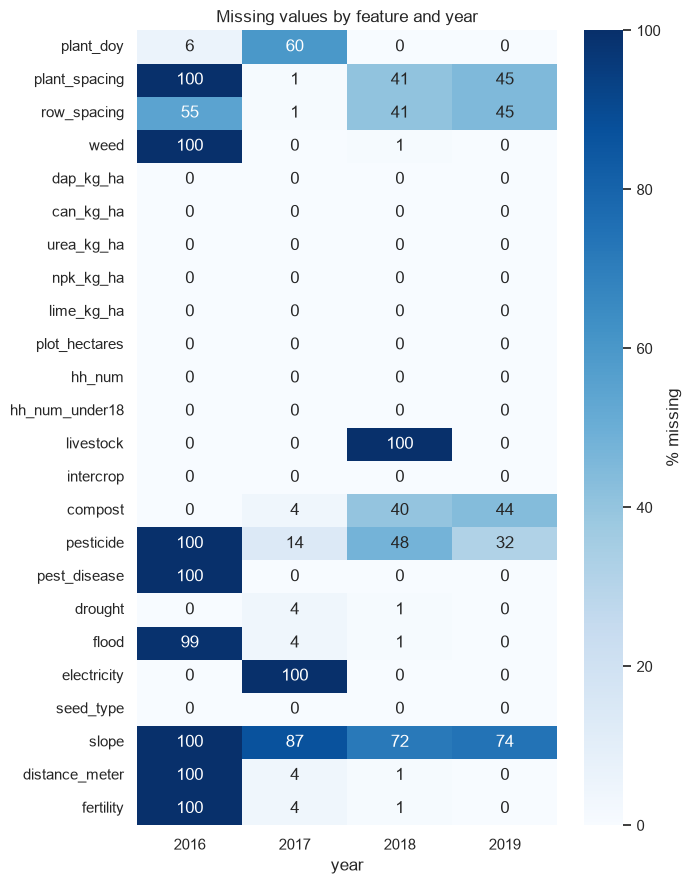

In [48]:
mt = data[PRACTICE_SET + SOIL].isna().mean().mul(100).round(1).rename("% missing").to_frame()
mt["group"] = mt.index.map(GROUP_OF)
print(mt.sort_values("% missing", ascending=False).head(20))
by_year = data.groupby("year")[PRACTICE_SET].agg(lambda s: s.isna().mean()*100).round(0).T
fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(by_year, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values by feature and year"); plt.tight_layout(); plt.savefig(f"{OUT}/missing_by_year.png", dpi=150); plt.show()

In [49]:
high = list(mt.sort_values("% missing", ascending=False).head(6).index)
by_district = data.groupby("district")[high].agg(lambda s: s.isna().mean() * 100).round(0)
print("% missing across the", len(by_district), "districts, for the six emptiest features")
print(by_district.describe().loc[["min", "50%", "max"]])
print("districts where the feature is 90% or more missing:"); print((by_district >= 90).sum())

% missing across the 41 districts, for the six emptiest features
     slope  pesticide  plant_spacing  row_spacing  livestock  compost
min    5.0        0.0            0.0          0.0        0.0      0.0
50%   83.0       45.0           45.0         37.0       24.0     24.0
max  100.0       75.0           60.0         57.0       68.0     52.0
districts where the feature is 90% or more missing:
slope            13
pesticide         0
plant_spacing     0
row_spacing       0
livestock         0
compost           0
dtype: int64


## 3. Outliers, capping and scaling

                   p1     p99      max  n_capped
plant_doy       33.00  132.00   181.00       264
plant_spacing   16.18   74.70   107.70       186
row_spacing     48.67  112.33   190.00       216
weed             0.00    3.00     5.00        14
dap_kg_ha        0.00  323.60   988.40       172
can_kg_ha        0.00  273.84   988.40       172
urea_kg_ha       0.00    0.00   247.10        88
npk_kg_ha        0.00    0.00   395.36        29
lime_kg_ha       0.00  247.10  1235.50        96
plot_hectares    0.04    1.42    12.14       305
hh_num           1.00   13.00    20.00       159
hh_num_under18   0.00    9.00    15.00       111
livestock        0.00   35.00   277.00       127


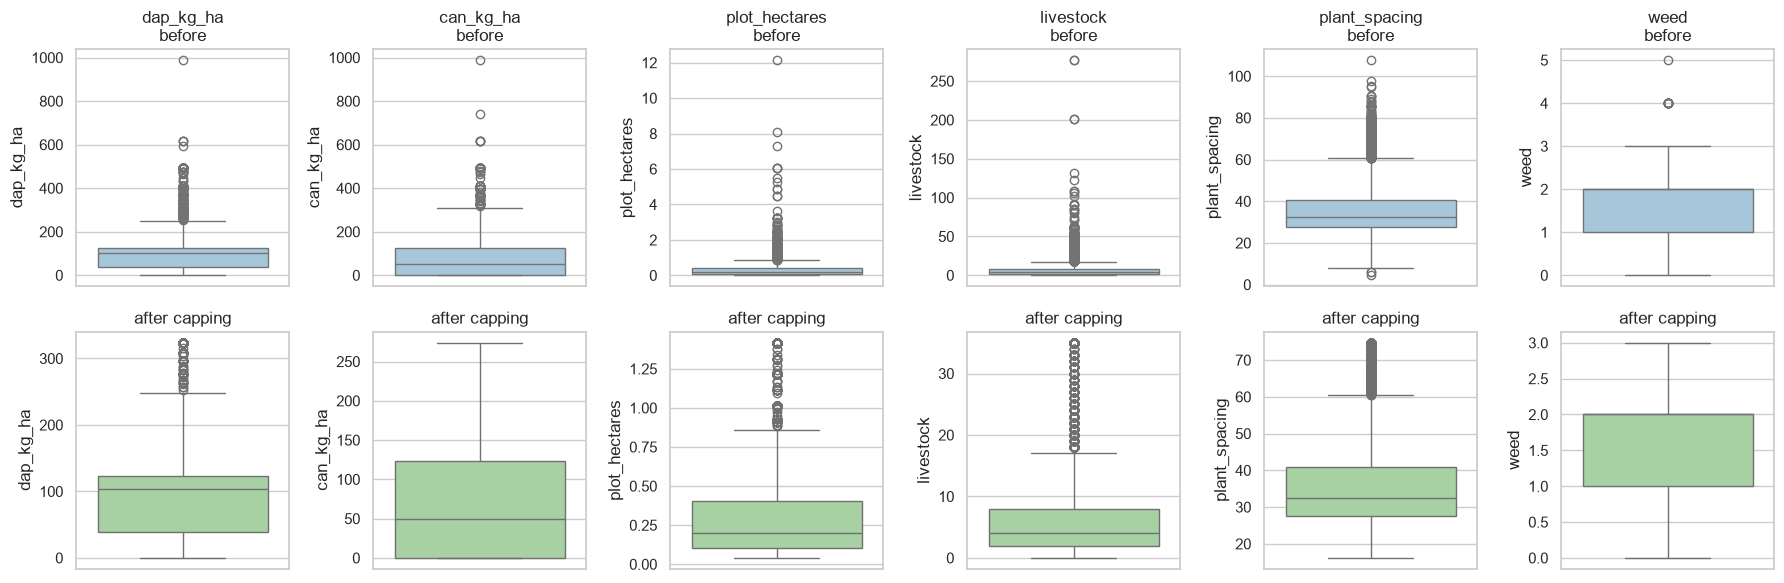

In [50]:
cap = pd.DataFrame({"p1": data[CONT].quantile(.01), "p99": data[CONT].quantile(.99), "max": data[CONT].max()})
cap["n_capped"] = [(data[c].lt(cap.p1[c]) | data[c].gt(cap.p99[c])).sum() for c in CONT]
print(cap.round(2))
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
show = ["dap_kg_ha", "can_kg_ha", "plot_hectares", "livestock", "plant_spacing", "weed"]
for i, c in enumerate(show):
    sns.boxplot(y=data[c], ax=axes[0, i], color="#9ecae1"); axes[0, i].set_title(f"{c}\nbefore")
    sns.boxplot(y=data[c].clip(cap.p1[c], cap.p99[c]), ax=axes[1, i], color="#a1d99b"); axes[1, i].set_title("after capping")
plt.tight_layout(); plt.savefig(f"{OUT}/outliers_capping.png", dpi=150); plt.show()

In [51]:
capped = data[CONT + SOIL].clip(cap.p1.reindex(CONT + SOIL).fillna(-np.inf), cap.p99.reindex(CONT + SOIL).fillna(np.inf), axis=1)
for c in SOIL: capped[c] = data[c].clip(data[c].quantile(.01), data[c].quantile(.99))
skew = capped.skew().rename("skewness")
CONT_ALL = CONT + SOIL
ROBUST = [c for c in CONT_ALL if abs(skew[c]) > 1]
STANDARD = [c for c in CONT_ALL if abs(skew[c]) <= 1]
print(skew.round(2).to_frame().assign(scaler=lambda d: np.where(d.index.isin(ROBUST), "Robust", "Standard")))

                 skewness    scaler
plant_doy            0.02  Standard
plant_spacing        1.24    Robust
row_spacing          0.31  Standard
weed                -0.86  Standard
dap_kg_ha            0.67  Standard
can_kg_ha            0.93  Standard
urea_kg_ha           0.00  Standard
npk_kg_ha            0.00  Standard
lime_kg_ha           5.80    Robust
plot_hectares        2.30    Robust
hh_num               0.42  Standard
hh_num_under18       0.46  Standard
livestock            2.04    Robust
soil_ph              0.83  Standard
soil_carbon          0.96  Standard
soil_nitrogen        1.13    Robust
soil_phosphorus      0.90  Standard
soil_potassium       1.05    Robust
soil_sand            0.85  Standard
soil_clay           -0.82  Standard


## 4. Exploration

### Yield distribution

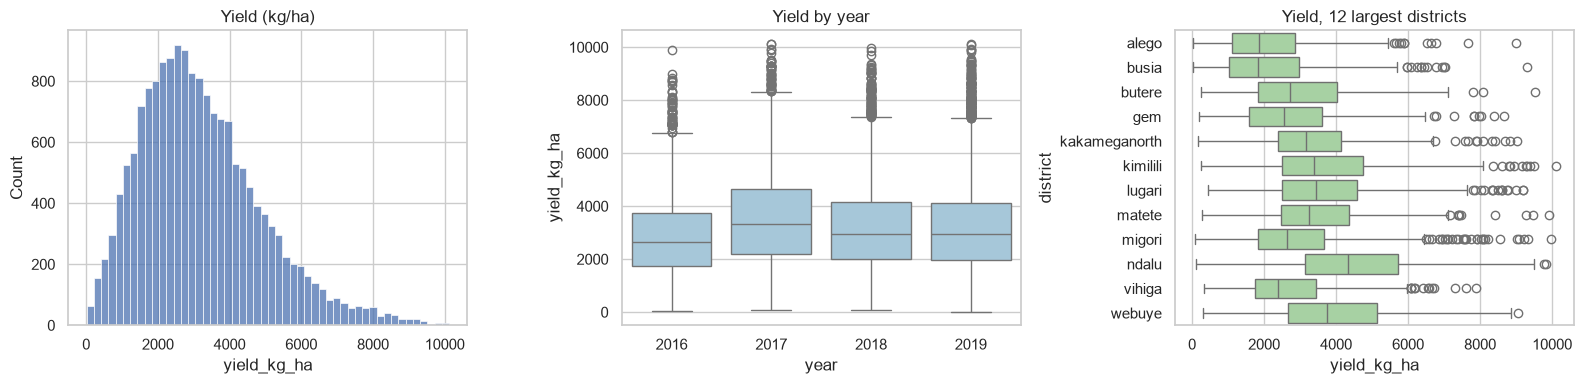

count    17127.0
mean      3204.0
std       1694.0
min         10.0
25%       1965.0
50%       2951.0
75%       4167.0
max      10125.0
Name: yield_kg_ha, dtype: float64
skewness: 0.81


In [52]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data.yield_kg_ha, bins=50, ax=ax[0], color="#4c72b0"); ax[0].set_title("Yield (kg/ha)")
sns.boxplot(data=data, x="year", y="yield_kg_ha", ax=ax[1], color="#9ecae1"); ax[1].set_title("Yield by year")
top = data.district.value_counts().head(12).index
sns.boxplot(data=data[data.district.isin(top)], y="district", x="yield_kg_ha", ax=ax[2], color="#a1d99b"); ax[2].set_title("Yield, 12 largest districts")
plt.tight_layout(); plt.savefig(f"{OUT}/yield_distribution.png", dpi=150); plt.show()
print(data.yield_kg_ha.describe().round(0))
print("skewness:", round(data.yield_kg_ha.skew(), 2))

### Correlation heatmap

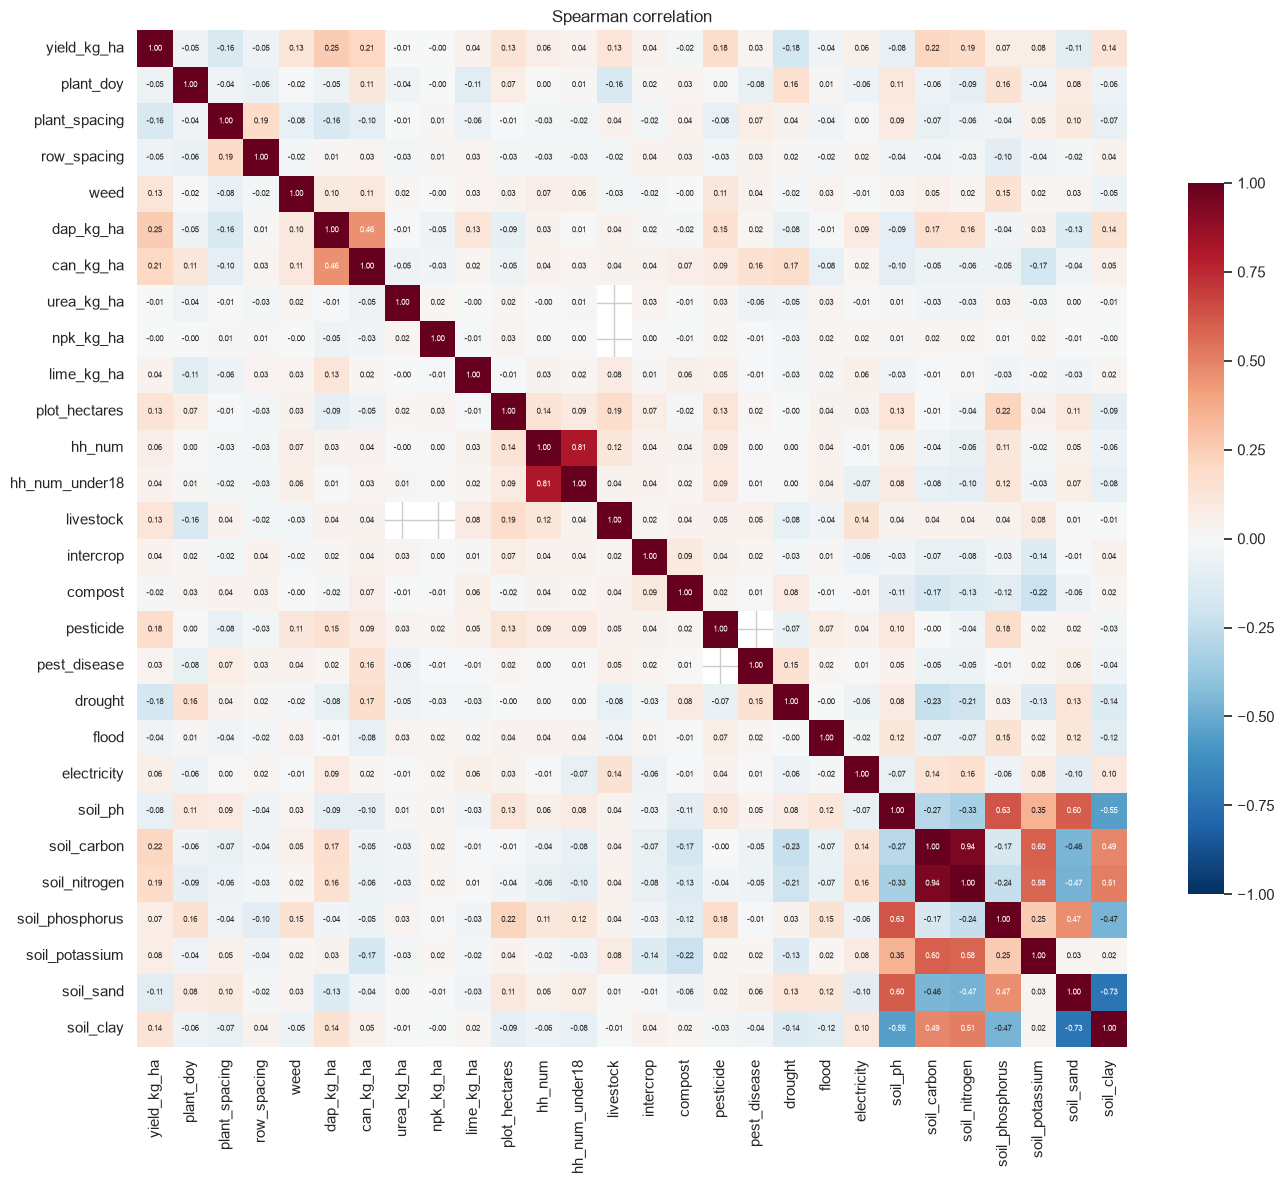

dap_kg_ha        0.250
soil_carbon      0.216
can_kg_ha        0.210
soil_nitrogen    0.194
pesticide        0.182
drought         -0.178
plant_spacing   -0.158
soil_clay        0.140
plot_hectares    0.134
livestock        0.132
weed             0.125
soil_sand       -0.112
Name: yield_kg_ha, dtype: float64

Feature pairs with |rho| > 0.7 (possible redundancy):
hh_num       hh_num_under18    0.81
soil_carbon  soil_nitrogen     0.94
soil_sand    soil_clay        -0.73
dtype: float64


In [53]:
corr_cols = ["yield_kg_ha"] + CONT + [c for c in BINARY] + SOIL
cm = data[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Spearman correlation"); plt.tight_layout(); plt.savefig(f"{OUT}/correlation_heatmap.png", dpi=150); plt.show()
print(cm["yield_kg_ha"].drop("yield_kg_ha").sort_values(key=abs, ascending=False).head(12).round(3))
hi = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("\nFeature pairs with |rho| > 0.7 (possible redundancy):")
print(hi[hi.abs() > 0.7].round(2))

### Scatter plots of yield against key numeric features 

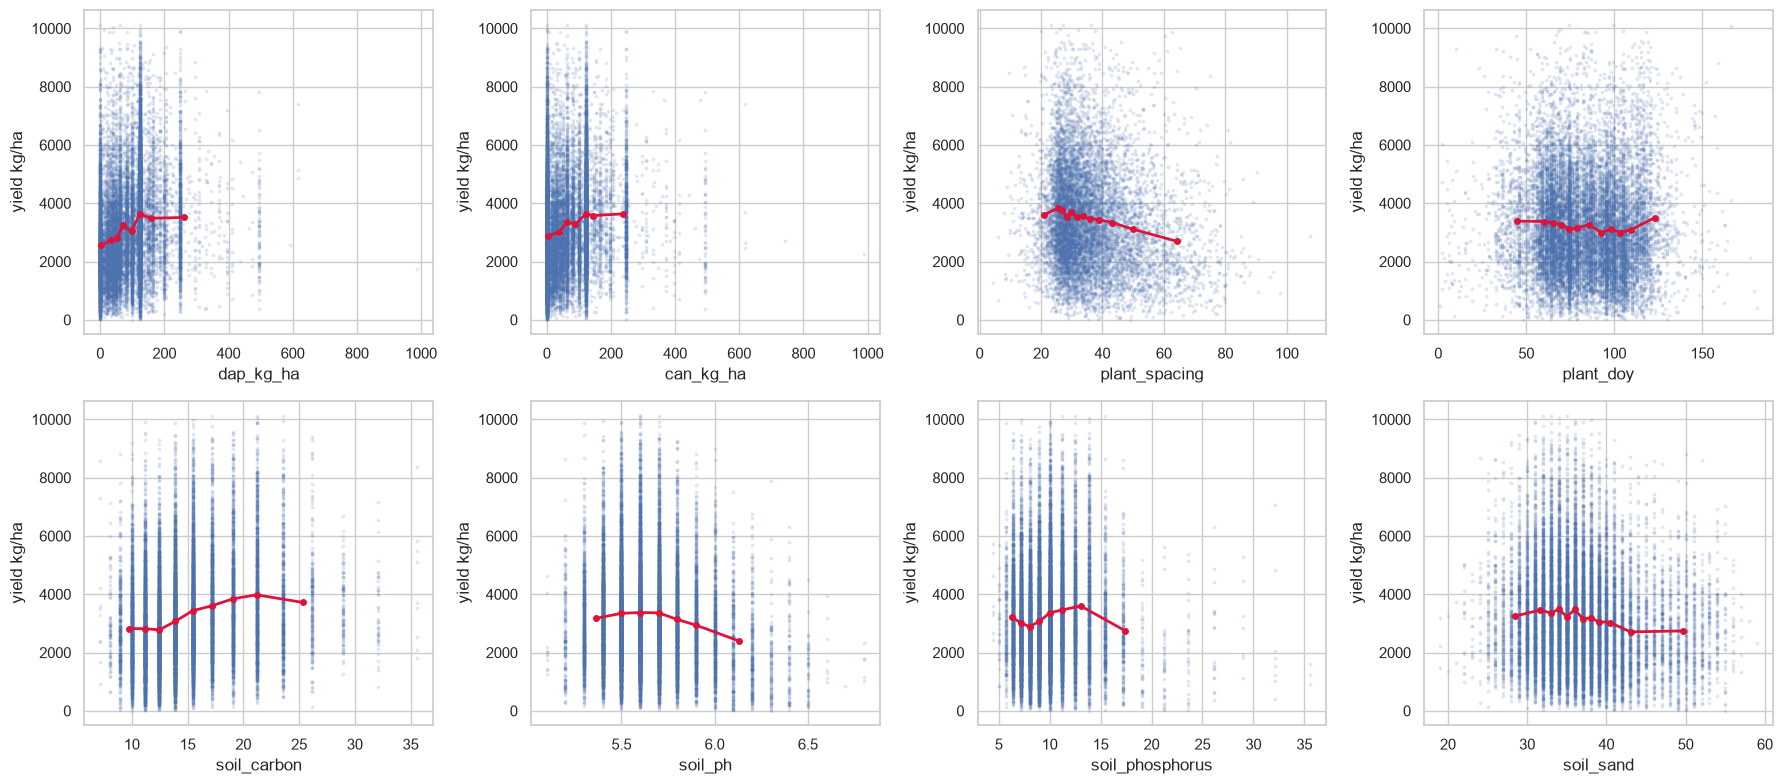

In [54]:
pairs = ["dap_kg_ha", "can_kg_ha", "plant_spacing", "plant_doy", "soil_carbon", "soil_ph", "soil_phosphorus", "soil_sand"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), pairs):
    d = data[[c, "yield_kg_ha"]].dropna()
    ax.scatter(d[c], d.yield_kg_ha, s=3, alpha=.12, color="#4c72b0")
    b = pd.qcut(d[c], 12, duplicates="drop"); g = d.groupby(b, observed=True).agg(x=(c, "mean"), y=("yield_kg_ha", "mean"))
    ax.plot(g.x, g.y, color="crimson", lw=2, marker="o", ms=4); ax.set_xlabel(c); ax.set_ylabel("yield kg/ha")
plt.tight_layout(); plt.savefig(f"{OUT}/scatter_key_features.png", dpi=150); plt.show()

### Hypothesis tests on the group means
A difference between group averages only means something if it is unlikely to be chance. For each comparison I show the two means, a Welch t test (it does not assume equal variances), a Mann Whitney or Kruskal Wallis test (it does not assume a normal shape, which matters because yield is skewed), a bootstrap 95% interval for the difference, and an effect size. The p values are adjusted for the number of tests with the Holm method.

With more than 20,000 records almost any difference is significant, so the effect size is what shows whether a difference is big enough to matter.

In [55]:
from statsmodels.stats.multitest import multipletests
rng = np.random.default_rng(SEED)
def boot_ci(a, b, n=2000):
    a, b = np.asarray(a), np.asarray(b)
    d = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return np.percentile(d, [2.5, 97.5])
rows = []
tests = {"Hybrid vs local seed": ("seed_group", "hybrid", "local"),
         "Compost used vs not": ("compost", 1, 0), "Pesticide used vs not": ("pesticide", 1, 0),
         "Intercropped vs not": ("intercrop", 1, 0), "Drought reported vs not": ("drought", 1, 0),
         "Lime used vs not": ("lime_used", 1, 0), "DAP used vs not": ("dap_used", 1, 0)}
t = data.copy()
t["seed_group"] = pd.Series(np.where(t.seed_type.fillna("").str.contains("local"), "local", "hybrid"), index=t.index).where(t.seed_type.notna())
t["lime_used"] = np.where(t.lime_kg_ha.isna(), np.nan, (t.lime_kg_ha > 0).astype(float))
t["dap_used"]  = np.where(t.dap_kg_ha.isna(), np.nan, (t.dap_kg_ha > 0).astype(float))
for name, (col, g1, g0) in tests.items():
    a = t.loc[t[col] == g1, "yield_kg_ha"].dropna(); b = t.loc[t[col] == g0, "yield_kg_ha"].dropna()
    tt = stats.ttest_ind(a, b, equal_var=False); mw = stats.mannwhitneyu(a, b)
    sp = np.sqrt((a.var() + b.var()) / 2); lo, hi = boot_ci(a, b)
    rows.append([name, len(a), len(b), a.mean(), b.mean(), a.mean()-b.mean(), lo, hi, (a.mean()-b.mean())/sp, tt.pvalue, mw.pvalue])
res = pd.DataFrame(rows, columns=["comparison","n_1","n_0","mean_1","mean_0","diff","ci_low","ci_high","cohens_d","p_welch","p_mannwhitney"])
res["p_welch_holm"] = multipletests(res.p_welch, method="holm")[1]
res["p_mw_holm"] = multipletests(res.p_mannwhitney, method="holm")[1]
print(res.round(3).to_string(index=False))

             comparison   n_1   n_0   mean_1   mean_0     diff   ci_low  ci_high  cohens_d  p_welch  p_mannwhitney  p_welch_holm  p_mw_holm
   Hybrid vs local seed 14126  3001 3418.042 2194.898 1223.144 1168.423 1276.463     0.811    0.000          0.000         0.000      0.000
    Compost used vs not  3953  8999 3213.802 3304.866  -91.063 -156.370  -23.323    -0.054    0.004          0.023         0.004      0.023
  Pesticide used vs not  2424  6692 3823.321 3128.947  694.375  613.941  777.800     0.404    0.000          0.000         0.000      0.000
    Intercropped vs not 12241  4886 3231.204 3134.872   96.331   36.833  153.898     0.056    0.001          0.000         0.002      0.000
Drought reported vs not  5498 11420 2766.629 3406.797 -640.168 -691.019 -588.684    -0.392    0.000          0.000         0.000      0.000
       Lime used vs not   788 16338 3475.076 3190.613  284.463  169.278  404.439     0.170    0.000          0.000         0.000      0.000
        DAP used vs 

In [56]:
# comparisons with more than two groups (ANOVA and Kruskal Wallis, eta squared as the effect size)
def multi(col, order=None):
    g = [v.dropna().values for _, v in t.groupby(col)["yield_kg_ha"] if v.notna().sum() > 30]
    f = stats.f_oneway(*g); k = stats.kruskal(*g)
    grand = t["yield_kg_ha"].mean(); ss_b = sum(len(x)*(x.mean()-grand)**2 for x in g); ss_t = ((t["yield_kg_ha"]-grand)**2).sum()
    return [col, len(g), f.pvalue, k.pvalue, ss_b/ss_t]
mres = pd.DataFrame([multi(c) for c in ["year", "weed", "slope", "fertility", "distance_meter"]], columns=["grouping","groups","p_anova","p_kruskal","eta_squared"])
print(mres.round(4).to_string(index=False))
print(t.groupby("year").yield_kg_ha.agg(["mean","median","count"]).round(0))
print(t.groupby("weed").yield_kg_ha.agg(["mean","count"]).round(0))
res.to_csv(f"{OUT}/hypothesis_tests.csv", index=False)

      grouping  groups  p_anova  p_kruskal  eta_squared
          year       4   0.0000     0.0000       0.0192
          weed       4   0.0000     0.0000       0.0263
         slope       5   0.1473     0.1960       0.0011
     fertility       5   0.0000     0.0000       0.0281
distance_meter       6   0.0023     0.0198       0.0035
        mean  median  count
year                       
2016  2849.0  2637.0   3722
2017  3551.0  3329.0   3941
2018  3198.0  2930.0   4214
2019  3198.0  2944.0   5250
        mean  count
weed               
0.0   3833.0    390
1.0   2783.0   3096
2.0   3455.0   9315
3.0   3263.0    553
4.0   3605.0     13
5.0   6750.0      1


## 5. Assumptions

1. A positive crop cut yield is a real measurement. Records with zero yield are treated as failed or missing measurements and removed.
2. Crop cut yield is the true yield of the field, with measurement noise that is not related to the features.
3. The farmer reported variables (pests, drought, flooding, soil fertility, planting date, weeding) are recalled with some error, which weakens relationships but does not create them.
4. Fertiliser and lime above 2,000 kg per hectare, weeding more than 6 times and planting outside January to June are entry errors. They are set to missing and the row is kept.
5. A zero in a column such as fertiliser is a real zero (not used) when the question was answered, and a missing value only when the answer is blank.
6. Missing values are filled with the median (or the most common category) and a missing indicator is kept, so the model can still use the fact that something was missing.
7. Livestock is cows plus goats plus chickens. If one animal type was not recorded it counts as zero, as long as at least one type was recorded.
8. Soil values are modelled estimates at about 1 km, not measurements at the farm, so they smooth over differences between neighbouring fields.
9. Fields in the same district are more alike than fields in different districts, so the validation holds out whole districts.
10. The data are repeated cross sections. The same farmer is not followed over time, so all findings are associations and not causes.
11. Season length (harvest date minus planting date) is partly decided by the yield itself, so it is not a predictor in the main models and is only used in one check. Drought is a weather shock reported by the farmer, so I treat it as a field condition and not a practice.
12. All farmers are in one programme, so the results may not hold for other smallholders.
13. The 2020 season is the final test and is not used for any choice. The model is built on 2016 to 2019, and a new season can differ in weather and prices in ways the features do not capture.

## 6. Preprocessing pipelines

Numeric, binary and categorical columns are handled in separate pipelines and joined with a ColumnTransformer.

* Continuous columns: cap, fill missing values with the median (keeping a missing indicator), then scale
* Binary columns: fill with the most common value (keeping a missing indicator)
* Categorical columns: fill with the label `missing`, then one hot encode, grouping rare categories and ignoring unseen ones

Imputation is in the pipeline even where there are no gaps today, because new records will have blanks when the model is used. The Winsorizer below is my own small transformer so that the caps are learned on the training rows only.

In [57]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

class Winsorizer(BaseEstimator, TransformerMixin):
    # caps every column at the percentiles found in the training data
    def __init__(self, lower=1, upper=99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanpercentile(X, self.lower, axis=0)
        self.hi_ = np.nanpercentile(X, self.upper, axis=0)
        self.n_features_in_ = X.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, names=None):
        return np.asarray(names, dtype=object)
    def set_output(self, *, transform=None):
        return self

def build_preprocessor(cont_robust, cont_standard, binary, categorical, scale=True):
    def cont(scaler):
        steps = [("cap", Winsorizer(1, 99)), ("impute", SimpleImputer(strategy="median", add_indicator=True))]
        if scale:
            steps.append(("scale", scaler))
        return Pipeline(steps)
    parts = []
    if cont_robust:   parts.append(("cont_robust", cont(RobustScaler()), cont_robust))
    if cont_standard: parts.append(("cont_standard", cont(StandardScaler()), cont_standard))
    if binary:
        parts.append(("binary", Pipeline([("impute", SimpleImputer(strategy="most_frequent", add_indicator=True))]), binary))
    if categorical:
        parts.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False))]), categorical))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=True)

def make_prep(cols, scale):
    return build_preprocessor([c for c in ROBUST if c in cols], [c for c in STANDARD if c in cols],
                              [c for c in BINARY if c in cols], [c for c in CAT if c in cols], scale=scale)
prep_demo = make_prep(FEATURE_SETS["Practices + soil"], scale=True)
Xd = prep_demo.fit_transform(data[PRACTICE_SET + SOIL])
print("transformed shape:", Xd.shape, "| NaN left:", int(np.isnan(Xd).sum()))
print(prep_demo)

transformed shape: (17127, 73) | NaN left: 0
ColumnTransformer(transformers=[('cont_robust',
                                 Pipeline(steps=[('cap', Winsorizer()),
                                                 ('impute',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scale', RobustScaler())]),
                                 ['plant_spacing', 'lime_kg_ha',
                                  'plot_hectares', 'livestock', 'soil_nitrogen',
                                  'soil_potassium']),
                                ('cont_standard',
                                 Pipeline(steps=[('cap', Winsorizer()),
                                                 ('impute',
                                                  SimpleImputer(add_i...
                                                                strategy=

In [58]:
# a record with blanks should still go through the pipeline
probe = data[PRACTICE_SET + SOIL].iloc[[0]].copy()
probe.loc[:, ["dap_kg_ha", "plant_spacing", "seed_type", "soil_ph", "drought"]] = np.nan
print("record with blanks transforms to a finite row:", bool(np.isfinite(prep_demo.transform(probe)).all()))

record with blanks transforms to a finite row: True


## 7. Modelling

The main model is XGBoost, which suits mixed tabular data of this size and is the model in my proposal. A random forest is fitted alongside it as a comparison. To see what the soil adds, both are fitted on three feature sets: practices only, soil only, and practices plus soil.

For validation I use 5 fold cross validation that holds out whole districts (`GroupKFold`), inside the training years only. The model settings are tuned inside each training set with a second district based split, so the held out districts are never used for tuning. This is called nested cross validation. Scores are RMSE and MAE in kg per hectare and R², pooled over all the held out districts. The 2020 test season is scored in section 9.

In [59]:
y = data["yield_kg_ha"].values; groups = data["district"].values

def make_estimator(kind, cols):
    # trees do not need scaling, but the pipeline keeps it so the preprocessing is complete
    prep = make_prep(cols, scale=True)
    if kind == "XGBoost":
        model = xgb.XGBRegressor(tree_method="hist", n_jobs=2, random_state=SEED, n_estimators=300)
        grid = {"model__n_estimators": [200, 300, 400], "model__max_depth": [3, 4, 5, 6], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__subsample": [0.7, 0.9], "model__colsample_bytree": [0.6, 0.8, 1.0], "model__min_child_weight": [5, 20, 50],
                "model__reg_lambda": [1, 10]}
    elif kind == "LightGBM":
        model = lgb.LGBMRegressor(n_estimators=300, n_jobs=2, random_state=SEED, verbose=-1)
        grid = {"model__num_leaves": [15, 31, 63], "model__learning_rate": [0.03, 0.05, 0.1], "model__min_child_samples": [20, 50, 100],
                "model__subsample": [0.7, 0.9], "model__subsample_freq": [1], "model__colsample_bytree": [0.6, 0.8, 1.0], "model__reg_lambda": [1, 10]}
    elif kind == "Random forest":
        model = RandomForestRegressor(n_estimators=100, n_jobs=2, random_state=SEED)
        grid = {"model__max_depth": [8, 12, 16], "model__min_samples_leaf": [5, 10, 20], "model__max_features": [0.3, 0.5]}
    else:
        model = CatBoostRegressor(iterations=300, thread_count=2, random_seed=SEED, verbose=0)
        grid = {"model__depth": [4, 6, 8], "model__learning_rate": [0.03, 0.05, 0.1], "model__l2_leaf_reg": [1, 3, 10]}
    search = lambda p, cv: RandomizedSearchCV(p, grid, n_iter=3 if kind == "Random forest" else 4, cv=cv, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1)
    return Pipeline([("prep", prep), ("model", model)]), search

def nested_cv(kind, cols, outer_k=5, inner_k=3):
    X = data[cols]; oof = np.zeros(len(y)); fold_rows = []; best = []
    for i, (tr, te) in enumerate(GroupKFold(outer_k).split(X, y, groups)):
        pipe, search = make_estimator(kind, cols)
        inner = list(GroupKFold(inner_k).split(X.iloc[tr], y[tr], groups[tr]))
        s = search(pipe, inner).fit(X.iloc[tr], y[tr])
        p = s.predict(X.iloc[te]); oof[te] = p; best.append(s.best_params_)
        fold_rows.append({"fold": i, "rmse": mean_squared_error(y[te], p) ** 0.5, "n_districts": len(set(groups[te]))})
    return oof, pd.DataFrame(fold_rows), best

def summarise(oof):
    return {"RMSE": mean_squared_error(y, oof) ** 0.5, "MAE": mean_absolute_error(y, oof), "R2": r2_score(y, oof)}

# baseline: always predict the training mean
base = np.zeros(len(y))
for tr, te in GroupKFold(5).split(data, y, groups): base[te] = y[tr].mean()
print("Baseline (training mean) pooled:", {k: round(v, 3) for k, v in summarise(base).items()})

Baseline (training mean) pooled: {'RMSE': 1698.118, 'MAE': 1339.73, 'R2': -0.005}


In [60]:
results, oofs, folds, bests = [], {}, {}, {}
t0 = time.time()
for fs_name, cols in FEATURE_SETS.items():
    for kind in ["XGBoost", "Random forest"]:
        oof, fr, best = nested_cv(kind, cols)
        m = summarise(oof); oofs[(fs_name, kind)] = oof; folds[(fs_name, kind)] = fr; bests[(fs_name, kind)] = best
        results.append({"features": fs_name, "model": kind, **m, "fold_RMSE_sd": fr.rmse.std()})
        print(f"{fs_name:18s} {kind:14s} RMSE {m['RMSE']:7.0f}  MAE {m['MAE']:7.0f}  R2 {m['R2']:.3f}   [{time.time()-t0:5.0f}s]")
res_df = pd.DataFrame(results)
res_df.to_csv(f"{OUT}/model_metrics.csv", index=False)

Practices only     XGBoost        RMSE    1525  MAE    1183  R2 0.190   [   51s]
Practices only     Random forest  RMSE    1529  MAE    1189  R2 0.186   [   86s]
Soil only          XGBoost        RMSE    1624  MAE    1280  R2 0.081   [  117s]
Soil only          Random forest  RMSE    1619  MAE    1277  R2 0.087   [  135s]
Practices + soil   XGBoost        RMSE    1502  MAE    1169  R2 0.215   [  192s]
Practices + soil   Random forest  RMSE    1520  MAE    1187  R2 0.196   [  234s]


RMSE (kg/ha), districts not seen in training
model             Random forest  XGBoost
features                                
Practices only           1529.0   1525.0
Soil only                1619.0   1624.0
Practices + soil         1520.0   1502.0

R2
model             Random forest  XGBoost
features                                
Practices only            0.186    0.190
Soil only                 0.087    0.081
Practices + soil          0.196    0.215


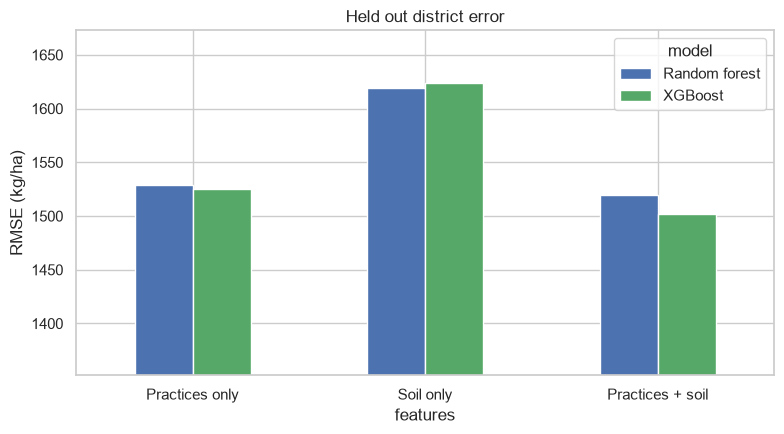

In [61]:
tab = res_df.pivot(index="features", columns="model", values="RMSE").loc[list(FEATURE_SETS)].round(0)
print("RMSE (kg/ha), districts not seen in training"); print(tab)
print(); print("R2"); print(res_df.pivot(index="features", columns="model", values="R2").loc[list(FEATURE_SETS)].round(3))
ax = tab.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#4c72b0", "#55a868", "#c44e52"][::-1][::-1])
ax.set_ylabel("RMSE (kg/ha)"); ax.set_title("Held out district error"); ax.set_ylim(tab.values.min() * .9, tab.values.max() * 1.03)
plt.tight_layout(); plt.savefig(f"{OUT}/model_comparison.png", dpi=150); plt.show()

In [62]:
def district_boot(a, b, n=1000):
    ua = np.unique(groups); idx = {u: np.where(groups == u)[0] for u in ua}; rng = np.random.default_rng(SEED); out = []
    for _ in range(n):
        s = np.concatenate([idx[u] for u in rng.choice(ua, len(ua))])
        out.append(mean_squared_error(y[s], a[s]) ** .5 - mean_squared_error(y[s], b[s]) ** .5)
    return np.percentile(out, [2.5, 50, 97.5])
for kind in ["XGBoost", "Random forest"]:
    lo, med, hi = district_boot(oofs[("Practices only", kind)], oofs[("Practices + soil", kind)])
    r0 = res_df.query("features=='Practices only' and model==@kind").RMSE.iloc[0]
    print(f"{kind:14s} RMSE gain from adding soil: {med:6.1f} kg/ha  (95% interval {lo:6.1f} to {hi:6.1f})  = {med/r0:.1%} of the error")

XGBoost        RMSE gain from adding soil:   21.8 kg/ha  (95% interval   -1.5 to   53.8)  = 1.4% of the error
Random forest  RMSE gain from adding soil:    8.8 kg/ha  (95% interval  -15.7 to   35.7)  = 0.6% of the error


## Trying to improve the R²

The R² of about 0.2 is low, so this section tests what can be done about it and where the remaining error comes from. It follows what the course book teaches on evaluation, tuning and feature engineering.

* Report the spread of the fold scores and the gain over the baseline, not one number
* Score the same predictions at field, district by season and district level, and compare with a random split and a year held out split
* Try a better tuning method (Optuna with early stopping) inside the nested loop
* Try engineered features, a log target, location and a blend, one at a time, on the same folds

In [63]:
# spread of the fold scores, and the gain over the baseline, for every model above (same district folds)
splits = list(GroupKFold(5).split(data, y, groups))
rows = []
for (fs_name, kind), o in oofs.items():
    r2f = [r2_score(y[te], o[te]) for _, te in splits]; rmf = [mean_squared_error(y[te], o[te]) ** .5 for _, te in splits]
    rows.append({"features": fs_name, "model": kind, "R2 mean": np.mean(r2f), "R2 sd": np.std(r2f), "RMSE mean": np.mean(rmf), "RMSE sd": np.std(rmf)})
base_rmse = mean_squared_error(y, base) ** .5
disp = pd.DataFrame(rows); disp["lift over baseline (RMSE)"] = 1 - disp["RMSE mean"] / base_rmse
print(f"baseline (training mean) RMSE: {base_rmse:.0f} kg/ha"); print(disp.round(3).to_string(index=False))
disp.to_csv(f"{OUT}/model_dispersion.csv", index=False)

baseline (training mean) RMSE: 1698 kg/ha
        features         model  R2 mean  R2 sd  RMSE mean  RMSE sd  lift over baseline (RMSE)
  Practices only       XGBoost    0.179  0.061   1524.134   30.367                      0.102
  Practices only Random forest    0.175  0.046   1528.287   37.890                      0.100
       Soil only       XGBoost    0.068  0.076   1623.873   34.298                      0.044
       Soil only Random forest    0.074  0.076   1618.276   38.497                      0.047
Practices + soil       XGBoost    0.203  0.073   1500.961   32.066                      0.116
Practices + soil Random forest    0.184  0.067   1518.792   37.544                      0.106


### The same predictions at three levels
Field level R² is low because two fields in the same district with the same soil and practices can differ a lot (weather, pests, labour, noise in the crop cut). Averaging removes much of that noise. The district averages are not a separate model, they are the field predictions averaged, so they should not be compared directly with the field level score.

                         level  units    R2  RMSE (kg/ha)
              individual field  17127 0.215      1501.527
district x season (20+ fields)    131 0.510       611.535
              district average     41 0.641       524.635


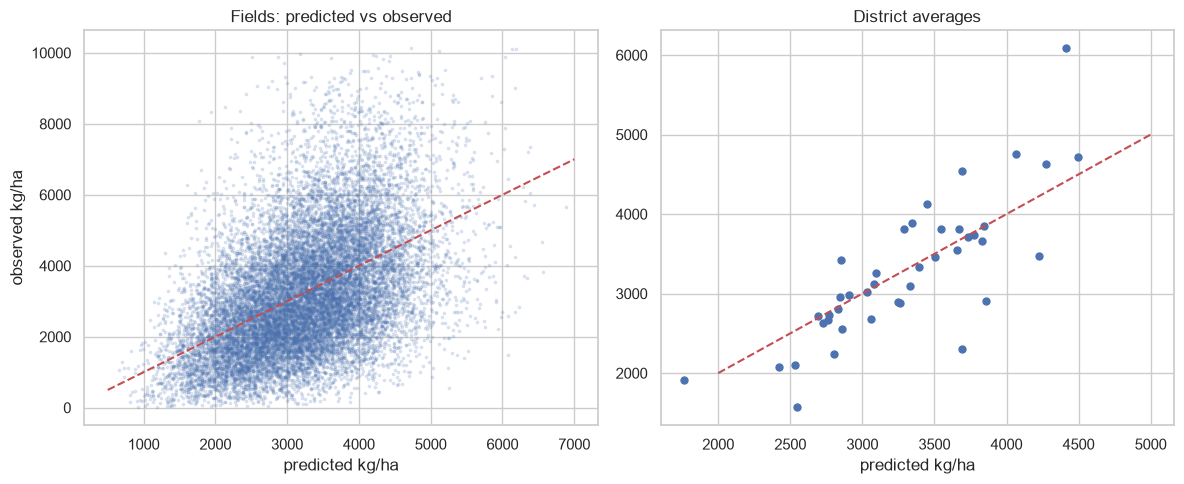

In [64]:
best_oof = oofs[("Practices + soil", "XGBoost")]
lv = pd.DataFrame({"district": groups, "year": data.year.values, "y": y, "p": best_oof})
dist = lv.groupby("district")[["y", "p"]].mean()
dy = lv.groupby(["district", "year"]).filter(lambda g: len(g) >= 20).groupby(["district", "year"])[["y", "p"]].mean()
lev = pd.DataFrame({"level": ["individual field", "district x season (20+ fields)", "district average"],
                    "units": [len(lv), len(dy), len(dist)],
                    "R2": [r2_score(y, best_oof), r2_score(dy.y, dy.p), r2_score(dist.y, dist.p)],
                    "RMSE (kg/ha)": [mean_squared_error(y, best_oof) ** .5, mean_squared_error(dy.y, dy.p) ** .5, mean_squared_error(dist.y, dist.p) ** .5]})
print(lev.round(3).to_string(index=False)); lev.to_csv(f"{OUT}/r2_by_level.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(lv.p, lv.y, s=3, alpha=.15); ax[0].plot([500, 7000], [500, 7000], "r--"); ax[0].set_title("Fields: predicted vs observed"); ax[0].set_xlabel("predicted kg/ha"); ax[0].set_ylabel("observed kg/ha")
ax[1].scatter(dist.p, dist.y, s=25); ax[1].plot([2000, 5000], [2000, 5000], "r--"); ax[1].set_title("District averages"); ax[1].set_xlabel("predicted kg/ha")
plt.tight_layout(); plt.savefig(f"{OUT}/predicted_vs_observed.png", dpi=150); plt.show()

### Where the errors are
The overall score hides who the model is wrong for. These tables split the held out predictions from the cross validation by year, by observed yield band and by how many records a district has, and list the districts with the largest and smallest error. For yield bands the model will always look biased, because fields with very high or very low yield cannot be predicted from the features, so predictions are pulled toward the middle.

In [65]:
def subgroup_table(obs, pred, by):
    g = pd.DataFrame({"by": by, "y": obs, "p": pred}); rows = []
    for k, d in g.groupby("by", observed=True):
        rows.append({"group": k, "n": len(d), "mean observed": d.y.mean(), "mean predicted": d.p.mean(),
                     "bias (pred minus obs)": d.p.mean() - d.y.mean(), "RMSE": mean_squared_error(d.y, d.p) ** .5, "MAE": mean_absolute_error(d.y, d.p)})
    return pd.DataFrame(rows).set_index("group")

dist_n = data.groupby("district")["yield_kg_ha"].transform("size").values
sub = {"By year": subgroup_table(y, best_oof, data.year.values),
       "By observed yield band (fifths)": subgroup_table(y, best_oof, pd.qcut(y, 5)),
       "By district size (records)": subgroup_table(y, best_oof, pd.cut(dist_n, [0, 150, 400, 10**6], labels=["under 150", "150 to 400", "over 400"]))}
for k, v in sub.items(): print(k); print(v.round(0).to_string()); print()
dd = subgroup_table(y, best_oof, groups).sort_values("RMSE")
print("Five districts with the smallest error"); print(dd.head(5).round(0).to_string()); print("\nFive districts with the largest error"); print(dd.tail(5).round(0).to_string())
pd.concat({k: v.reset_index() for k, v in {**sub, "By district": dd}.items()}).to_csv(f"{OUT}/error_by_subgroup_cv.csv")

By year
          n  mean observed  mean predicted  bias (pred minus obs)    RMSE     MAE
group                                                                            
2016   3722         2849.0          2909.0                   60.0  1387.0  1094.0
2017   3941         3551.0          3534.0                  -17.0  1568.0  1221.0
2018   4214         3198.0          3246.0                   47.0  1535.0  1199.0
2019   5250         3198.0          3211.0                   13.0  1502.0  1158.0

By observed yield band (fifths)
                          n  mean observed  mean predicted  bias (pred minus obs)    RMSE     MAE
group                                                                                            
(9.721, 1749.243]      3426         1165.0          2623.0                 1458.0  1657.0  1467.0
(1749.243, 2562.435]   3432         2166.0          3011.0                  844.0  1132.0   929.0
(2562.435, 3381.437]   3431         2960.0          3246.0                 

In [66]:
from sklearn.model_selection import KFold, GroupShuffleSplit
XGB_FIX = dict(n_estimators=3000, learning_rate=0.03, max_depth=4, min_child_weight=20, subsample=0.8, colsample_bytree=0.7,
               reg_lambda=5, tree_method="hist", n_jobs=2, random_state=SEED, early_stopping_rounds=60)

def fixed_cv(cols, split, logy=False):
    # fixed settings, early stopping. The preprocessing is fitted only on the rows the model trains on.
    o = np.zeros(len(y))
    for tr, te in split:
        Xtr_raw, ytr, gtr = data.iloc[tr][cols], y[tr], groups[tr]
        a, b = next(GroupShuffleSplit(1, test_size=.15, random_state=SEED).split(Xtr_raw, ytr, gtr))   # early stopping uses held out districts
        prep = make_prep(cols, scale=False)
        Xa, Xb = prep.fit_transform(Xtr_raw.iloc[a]), prep.transform(Xtr_raw.iloc[b])
        ya, yb = (np.log1p(ytr[a]), np.log1p(ytr[b])) if logy else (ytr[a], ytr[b])
        m = xgb.XGBRegressor(**XGB_FIX).fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
        p = m.predict(prep.transform(data.iloc[te][cols]))
        if logy: p = np.expm1(p) * np.mean(np.exp(ya - m.predict(Xa)))        # convert back, with a smearing correction
        o[te] = p
    return o

mc = FEATURE_SETS["Practices + soil"]
ev = []
for label, split in [("Whole districts held out (used in this study)", splits),
                     ("Whole years held out", list(GroupKFold(4).split(data, y, data.year.values))),
                     ("Random split (too optimistic)", list(KFold(5, shuffle=True, random_state=SEED).split(data)))]:
    o = fixed_cv(mc, split); ev.append({"split": label, "RMSE": mean_squared_error(y, o) ** .5, "R2": r2_score(y, o)}); print(ev[-1])
pd.DataFrame(ev).to_csv(f"{OUT}/evaluation_design.csv", index=False)

{'split': 'Whole districts held out (used in this study)', 'RMSE': 1530.8449891704745, 'R2': 0.18364869376409076}
{'split': 'Whole years held out', 'RMSE': 1553.5087727950995, 'R2': 0.1592980045870772}
{'split': 'Random split (too optimistic)', 'RMSE': 1454.0196688738545, 'R2': 0.26352972841867817}


### Engineered features, log target, location and blending
Each idea is added on its own to the practices plus soil features and scored on the same held out districts with the same fixed settings, so the only change is the idea.

* Engineered features: nitrogen and phosphate supplied (using the nutrient content of each fertiliser: DAP 18 to 46 to 0, CAN 26% N, urea 46% N, NPK 17 to 17 to 17), total fertiliser, spacing area (row spacing times plant spacing) and the soil carbon to nitrogen ratio
* Log target: yield is right skewed, so I fit log(1 + yield) and convert back
* Location: latitude and longitude, as a stand in for climate and altitude. They are not in my proposal's variable list, so this is an extension
* Year: the season effect. It cannot be known for a future season, so this is only a check
* Blend: the average of XGBoost and random forest

In [67]:
d_ = data
d_["n_kg_ha"]    = (0.18 * d_.dap_kg_ha).add(0.26 * d_.can_kg_ha, fill_value=0).add(0.46 * d_.urea_kg_ha, fill_value=0).add(0.17 * d_.npk_kg_ha, fill_value=0)
d_["p2o5_kg_ha"] = (0.46 * d_.dap_kg_ha).add(0.17 * d_.npk_kg_ha, fill_value=0)
d_["fert_total_kg_ha"] = d_[["dap_kg_ha", "can_kg_ha", "urea_kg_ha", "npk_kg_ha"]].sum(axis=1, min_count=1)
d_["spacing_area"] = d_.row_spacing * d_.plant_spacing
d_["soil_cn"] = d_.soil_carbon / d_.soil_nitrogen
ENG = ["n_kg_ha", "p2o5_kg_ha", "fert_total_kg_ha", "spacing_area", "soil_cn"]
for c in ENG + ["lat", "lon"]:                                   # scaler rule: robust if skewed after capping
    sk = d_[c].clip(d_[c].quantile(.01), d_[c].quantile(.99)).skew(); (ROBUST if abs(sk) > 1 else STANDARD).append(c)
STANDARD.append("year")
attempts = {"Main model (practices + soil)": (mc, False), "+ engineered features": (mc + ENG, False), "Log target": (mc, True),
            "+ engineered features, log target": (mc + ENG, True), "+ location (latitude, longitude)": (mc + ["lat", "lon"], False),
            "+ year (diagnostic)": (mc + ["year"], False), "+ engineered + location": (mc + ENG + ["lat", "lon"], False)}
att, att_oof = [], {}
for label, (cs, lg) in attempts.items():
    o = fixed_cv(cs, splits, logy=lg); att_oof[label] = o
    r2f = [r2_score(y[te], o[te]) for _, te in splits]
    att.append({"variant": label, "RMSE": mean_squared_error(y, o) ** .5, "R2": r2_score(y, o), "fold R2 mean": np.mean(r2f), "fold R2 sd": np.std(r2f)})
rf_o = oofs[("Practices + soil", "Random forest")]; bl = .5 * att_oof["Main model (practices + soil)"] + .5 * rf_o
att.append({"variant": "Blend of XGBoost and random forest", "RMSE": mean_squared_error(y, bl) ** .5, "R2": r2_score(y, bl),
            "fold R2 mean": np.mean([r2_score(y[te], bl[te]) for _, te in splits]), "fold R2 sd": np.std([r2_score(y[te], bl[te]) for _, te in splits])})
att = pd.DataFrame(att); print(att.round(3).to_string(index=False)); att.to_csv(f"{OUT}/improvement_attempts.csv", index=False)

                           variant     RMSE    R2  fold R2 mean  fold R2 sd
     Main model (practices + soil) 1530.845 0.184         0.173       0.070
             + engineered features 1530.614 0.184         0.173       0.072
                        Log target 1518.269 0.197         0.185       0.076
 + engineered features, log target 1520.269 0.195         0.183       0.073
  + location (latitude, longitude) 1540.592 0.173         0.164       0.069
               + year (diagnostic) 1524.168 0.191         0.179       0.076
           + engineered + location 1533.635 0.181         0.171       0.064
Blend of XGBoost and random forest 1516.809 0.199         0.188       0.066


### Tuning with Optuna inside the nested loop
Learning rate, minimum child weight and the regularisation strength are searched on a log scale. The number of trees is fixed high and early stopping picks the right number. The preprocessing is fitted again inside every inner training fold, so nothing from a validation fold leaks into it. The outer districts never see the search, so the score is not just the luckiest trial.

In [68]:
import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 12
def space(t):
    return dict(learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True), max_depth=t.suggest_int("max_depth", 3, 8),
                min_child_weight=t.suggest_int("min_child_weight", 5, 200, log=True), subsample=t.suggest_float("subsample", 0.5, 1.0),
                colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0), reg_lambda=t.suggest_float("reg_lambda", 0.1, 50, log=True))

def optuna_nested(cols):
    o = np.zeros(len(y)); chosen = []
    for k, (tr, te) in enumerate(splits):
        Xtr_raw, ytr, gtr = data.iloc[tr][cols], y[tr], groups[tr]
        # inner folds: the preprocessing is fitted on each inner training part only
        inner = []
        for a, b in GroupKFold(3).split(Xtr_raw, ytr, gtr):
            pr = make_prep(cols, scale=False)
            inner.append((pr.fit_transform(Xtr_raw.iloc[a]), ytr[a], pr.transform(Xtr_raw.iloc[b]), ytr[b]))
        def objective(t):
            p = space(t); sc = []
            for Xa, ya, Xb, yb in inner:
                m = xgb.XGBRegressor(n_estimators=2000, early_stopping_rounds=40, tree_method="hist", n_jobs=2, random_state=SEED, **p)
                m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False); sc.append(mean_squared_error(yb, m.predict(Xb)) ** .5)
            return float(np.mean(sc))
        st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=6))
        st.optimize(objective, n_trials=N_TRIALS)
        p = st.best_params
        # final model for this outer fold, early stopping on a slice of the training districts
        a, b = next(GroupShuffleSplit(1, test_size=.15, random_state=SEED).split(Xtr_raw, ytr, gtr))
        pr = make_prep(cols, scale=False)
        Xa, Xb = pr.fit_transform(Xtr_raw.iloc[a]), pr.transform(Xtr_raw.iloc[b])
        m = xgb.XGBRegressor(n_estimators=3000, early_stopping_rounds=50, tree_method="hist", n_jobs=2, random_state=SEED, **p)
        m.fit(Xa, ytr[a], eval_set=[(Xb, ytr[b])], verbose=False)
        o[te] = m.predict(pr.transform(data.iloc[te][cols])); chosen.append({**p, "trees": m.best_iteration})
    return o, pd.DataFrame(chosen)

opt_res, opt_oof, opt_params = [], {}, {}
t0 = time.time()
for fs_name, cs in FEATURE_SETS.items():
    o, pr_ = optuna_nested(cs); opt_oof[fs_name] = o; opt_params[fs_name] = pr_
    r2f = [r2_score(y[te], o[te]) for _, te in splits]
    opt_res.append({"features": fs_name, "RMSE": mean_squared_error(y, o) ** .5, "R2": r2_score(y, o), "fold R2 mean": np.mean(r2f), "fold R2 sd": np.std(r2f)})
    print(opt_res[-1], f"[{time.time()-t0:.0f}s]", flush=True)
opt_df = pd.DataFrame(opt_res); opt_df.to_csv(f"{OUT}/optuna_nested_metrics.csv", index=False)
print(opt_df.round(3).to_string(index=False)); print(opt_params["Practices + soil"].round(3))

{'features': 'Practices only', 'RMSE': 1521.1558391796386, 'R2': 0.1939498265191999, 'fold R2 mean': np.float64(0.1830195055095823), 'fold R2 sd': np.float64(0.055180157938662315)} [132s]
{'features': 'Soil only', 'RMSE': 1648.0207110802946, 'R2': 0.053893581955669845, 'fold R2 mean': np.float64(0.041103627182709344), 'fold R2 sd': np.float64(0.06804982326190225)} [179s]
{'features': 'Practices + soil', 'RMSE': 1532.8199782643592, 'R2': 0.18154093632736945, 'fold R2 mean': np.float64(0.17147227436620546), 'fold R2 sd': np.float64(0.06813899565539519)} [337s]
        features     RMSE    R2  fold R2 mean  fold R2 sd
  Practices only 1521.156 0.194         0.183       0.055
       Soil only 1648.021 0.054         0.041       0.068
Practices + soil 1532.820 0.182         0.171       0.068
   learning_rate  max_depth  min_child_weight  subsample  colsample_bytree  reg_lambda  trees
0          0.054          4                46      0.570             0.575       0.975    316
1          0.02

### Random search against Optuna

In [69]:
cmp_ = pd.DataFrame({"features": list(FEATURE_SETS),
                     "XGBoost, random search (first run)": [res_df.query("features==@f and model=='XGBoost'").R2.iloc[0] for f in FEATURE_SETS],
                     "XGBoost, Optuna + early stopping": opt_df.R2.values})
print(cmp_.round(3).to_string(index=False))

        features  XGBoost, random search (first run)  XGBoost, Optuna + early stopping
  Practices only                               0.190                             0.194
       Soil only                               0.081                             0.054
Practices + soil                               0.215                             0.182


### Two other boosting libraries
A short check that the choice of library is not what holds the score down. LightGBM and CatBoost go through the same nested cross validation as XGBoost, on practices plus soil, with a small random search each.

In [70]:
gbm_rows = [{"model": "XGBoost (random search, first run)", **summarise(oofs[("Practices + soil", "XGBoost")])}]
t0 = time.time()
for kind in ["LightGBM", "CatBoost"]:
    o, fr, _ = nested_cv(kind, FEATURE_SETS["Practices + soil"])
    gbm_rows.append({"model": kind, **summarise(o)}); print(kind, {k: round(v, 3) for k, v in gbm_rows[-1].items() if k != "model"}, f"[{time.time()-t0:.0f}s]", flush=True)
gbm_df = pd.DataFrame(gbm_rows); print(gbm_df.round(3).to_string(index=False)); gbm_df.to_csv(f"{OUT}/other_boosting_libraries.csv", index=False)

LightGBM {'RMSE': 1501.492, 'MAE': 1168.186, 'R2': 0.215} [30s]
CatBoost {'RMSE': 1500.888, 'MAE': 1170.033, 'R2': 0.215} [162s]
                             model     RMSE      MAE    R2
XGBoost (random search, first run) 1501.527 1168.850 0.215
                          LightGBM 1501.492 1168.186 0.215
                          CatBoost 1500.888 1170.033 0.215


## 8. Explaining the model with SHAP

In [71]:
import shap
cols = FEATURE_SETS["Practices + soil"]; X = data[cols]
pipe, search = make_estimator("XGBoost", cols)
final = search(pipe, list(GroupKFold(5).split(X, y, groups))).fit(X, y)
print("final settings:", final.best_params_)
best_pipe = final.best_estimator_
Xt = pd.DataFrame(best_pipe.named_steps["prep"].transform(X), columns=best_pipe.named_steps["prep"].get_feature_names_out())

def to_feature(name):
    r = name.split("__", 1)[1] if "__" in name else name
    r = r.replace("missingindicator_", "")
    cands = [f for f in cols if r == f or r.startswith(f + "_")]
    return max(cands, key=len) if cands else r
fmap = [to_feature(c) for c in Xt.columns]
print("columns after preprocessing:", Xt.shape[1], "| mapped to", len(set(fmap)), "original features")

final settings: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 200, 'model__min_child_weight': 20, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
columns after preprocessing: 73 | mapped to 31 original features


                 mean |SHAP| (kg/ha)              group  rank
seed_type                 183.300003  Practice or input     1
can_kg_ha                 168.100006  Practice or input     2
drought                   155.899994              Field     3
dap_kg_ha                 144.100006  Practice or input     4
soil_carbon               127.099998               Soil     5
fertility                 121.000000              Field     6
plot_hectares             111.000000              Field     7
soil_phosphorus           110.699997               Soil     8
electricity                81.900002          Household     9
soil_nitrogen              80.099998               Soil    10
row_spacing                80.000000  Practice or input    11
soil_ph                    76.099998               Soil    12
pesticide                  64.400002  Practice or input    13
plant_doy                  59.799999  Practice or input    14
soil_clay                  53.700001               Soil    15


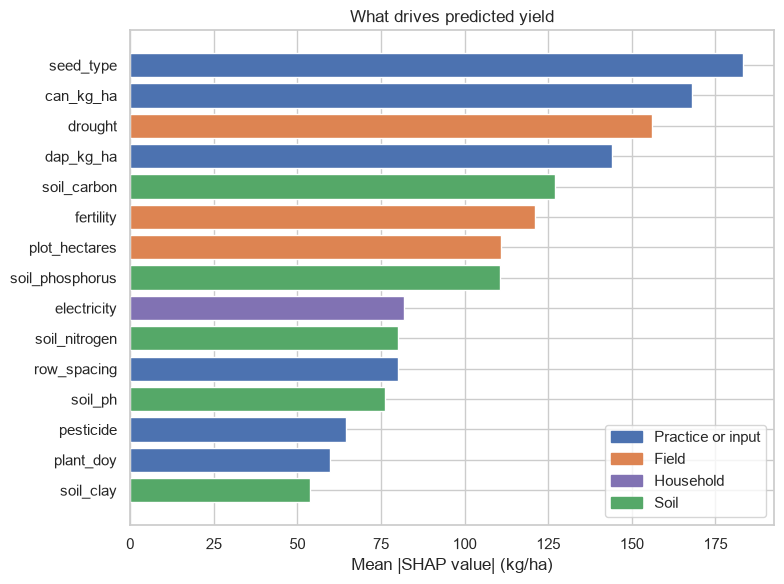

Share of total |SHAP| by group:
group
Field                0.227
Household            0.078
Practice or input    0.422
Soil                 0.272
Name: mean |SHAP| (kg/ha), dtype: float32


In [72]:
rng = np.random.default_rng(SEED)
s_idx = rng.choice(len(Xt), 3000, replace=False)
expl = shap.TreeExplainer(best_pipe.named_steps["model"])
sv = expl.shap_values(Xt.iloc[s_idx])
sv_f = pd.DataFrame(sv, columns=Xt.columns).T.groupby(fmap).sum().T          # SHAP values add up, so sum one hot and indicator columns
imp = sv_f.abs().mean().sort_values(ascending=False).rename("mean |SHAP| (kg/ha)").to_frame()
imp["group"] = imp.index.map(GROUP_OF); imp["rank"] = range(1, len(imp) + 1)
print(imp.head(15).round(1))
imp.to_csv(f"{OUT}/shap_importance.csv")
top = imp.head(15).iloc[::-1]
colors = top.group.map({"Practice or input": "#4c72b0", "Field": "#dd8452", "Household": "#8172b3", "Soil": "#55a868"})
fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(top.index, top.iloc[:, 0], color=colors)
ax.set_xlabel("Mean |SHAP value| (kg/ha)"); ax.set_title("What drives predicted yield")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in {"Practice or input": "#4c72b0", "Field": "#dd8452", "Household": "#8172b3", "Soil": "#55a868"}.items()], loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/shap_importance.png", dpi=150); plt.show()
col_ = "mean |SHAP| (kg/ha)"; print("Share of total |SHAP| by group:"); print((imp.groupby("group")[col_].sum() / imp[col_].sum()).round(3))

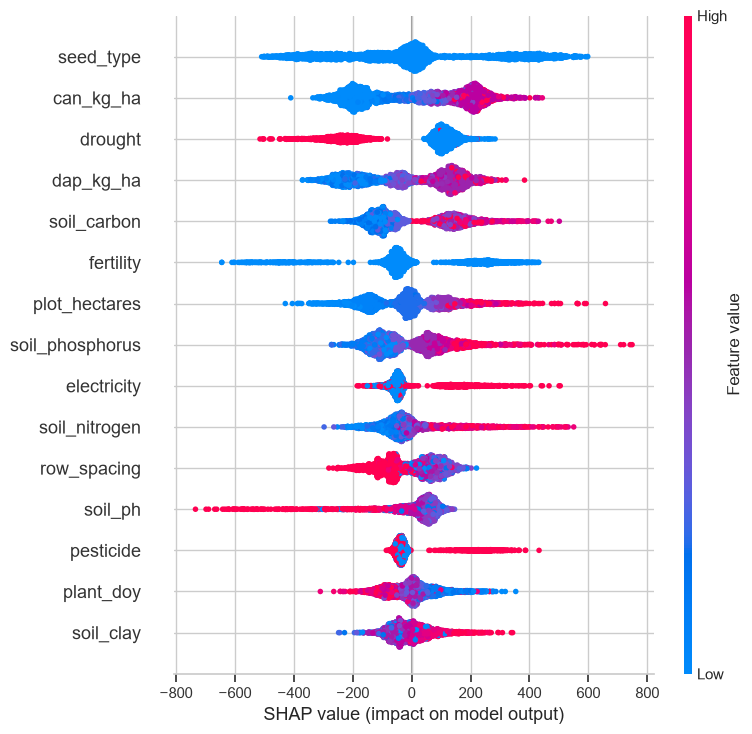

In [73]:
# SHAP summary plot, with the one hot columns merged back to the original features
Xf = pd.DataFrame({f: Xt.loc[:, [c for c, g in zip(Xt.columns, fmap) if g == f]].iloc[s_idx].mean(axis=1) for f in sv_f.columns})
plt.figure(); shap.summary_plot(sv_f.values, Xf, max_display=15, show=False); plt.tight_layout()
plt.savefig(f"{OUT}/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

In [74]:
# SHAP interaction values on a smaller sample, merged back to the original features
i_idx = rng.choice(len(Xt), 1200, replace=False)
siv = expl.shap_interaction_values(Xt.iloc[i_idx])
names = sorted(set(fmap)); M = np.zeros((len(Xt.columns), len(names)))
for j, f in enumerate(fmap): M[j, names.index(f)] = 1
agg = np.einsum("nab,ag,bh->ngh", siv, M, M)
I = np.abs(agg).mean(0); np.fill_diagonal(I, 0)
pairs = [(names[a], names[b], 2 * I[a, b]) for a in range(len(names)) for b in range(a + 1, len(names))]
ip = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "mean_abs_interaction"]).sort_values("mean_abs_interaction", ascending=False)
ip["pair_type"] = np.where((ip.feature_a.isin(SOIL)) ^ (ip.feature_b.isin(SOIL)), "practice x soil", "other")
main_eff = sv_f.iloc[:len(i_idx)].abs().mean()
print("Strongest interactions (kg/ha):"); print(ip.head(10).round(1).to_string(index=False))
print("\nStrongest practice x soil interactions:"); print(ip[ip.pair_type == "practice x soil"].head(10).round(1).to_string(index=False))
print(f"\nAverage size of an interaction vs average main effect: {ip.mean_abs_interaction.mean():.1f} vs {main_eff.mean():.1f} kg/ha")
ip.to_csv(f"{OUT}/shap_interactions.csv", index=False)

Strongest interactions (kg/ha):
    feature_a       feature_b  mean_abs_interaction       pair_type
    can_kg_ha       dap_kg_ha                  56.5           other
  row_spacing       seed_type                  32.0           other
    dap_kg_ha         drought                  30.7           other
      drought     soil_carbon                  30.3 practice x soil
    dap_kg_ha       seed_type                  25.6           other
soil_nitrogen soil_phosphorus                  25.5           other
  row_spacing     soil_carbon                  24.3 practice x soil
    can_kg_ha       seed_type                  23.4           other
      drought       seed_type                  22.9           other
      drought         soil_ph                  21.2 practice x soil

Strongest practice x soil interactions:
    feature_a     feature_b  mean_abs_interaction       pair_type
      drought   soil_carbon                  30.3 practice x soil
  row_spacing   soil_carbon                  24

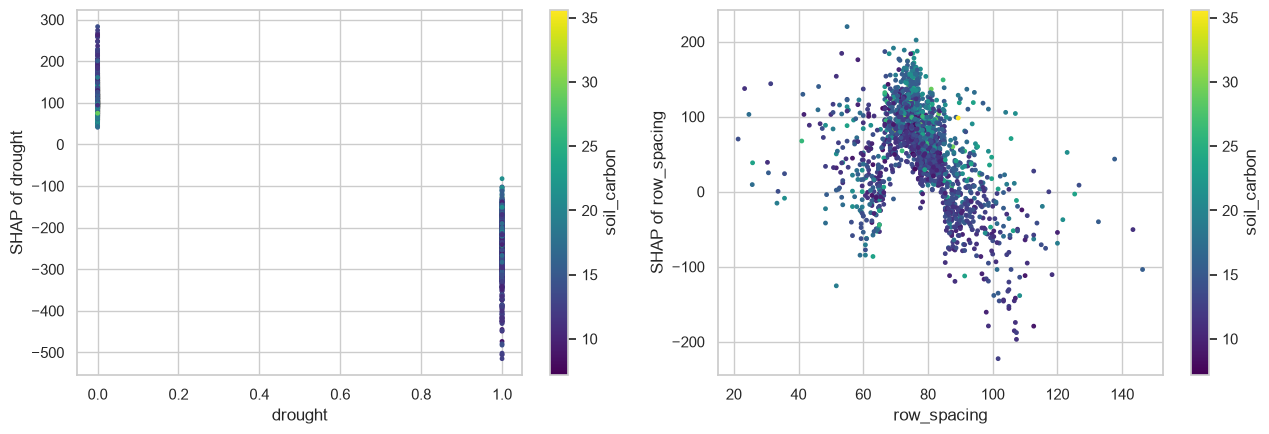

In [75]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ps = ip[(ip.pair_type == "practice x soil")]
ps = ps[ps.apply(lambda r: (r.feature_a if r.feature_b in SOIL else r.feature_b) in CONT + BINARY, axis=1)].head(2)
for a, (f, g) in zip(ax, ps[["feature_a", "feature_b"]].values):
    p, s_ = (f, g) if g in SOIL else (g, f)
    sc = a.scatter(data.iloc[s_idx][p].values, sv_f[p].values, c=data.iloc[s_idx][s_].values, s=6, cmap="viridis")
    a.set_xlabel(p); a.set_ylabel(f"SHAP of {p}"); plt.colorbar(sc, ax=a, label=s_)
plt.tight_layout(); plt.savefig(f"{OUT}/shap_dependence.png", dpi=150); plt.show()

### Effect of drought and season length
I rerun the main model without drought (a weather shock reported by the farmer, not a practice) and with season length added (to see how much of the score it borrows from the outcome). Same nested design, XGBoost, practices plus soil.

In [76]:
sens = []
base_cols = FEATURE_SETS["Practices + soil"]
(ROBUST if abs(data.season_length.skew()) > 1 else STANDARD).append("season_length")
for label, cols_s in [("Main model", base_cols), ("Without drought", [c for c in base_cols if c != "drought"]),
                      ("With season length", base_cols + ["season_length"])]:
    oof, fr, _ = nested_cv("XGBoost", cols_s)
    m = summarise(oof); sens.append({"run": label, **m}); print(f"{label:20s} RMSE {m['RMSE']:7.0f} R2 {m['R2']:.3f}")
pd.DataFrame(sens).to_csv(f"{OUT}/sensitivity.csv", index=False)

Main model           RMSE    1502 R2 0.215
Without drought      RMSE    1507 R2 0.208
With season length   RMSE    1499 R2 0.217


## 9. Final score on the 2020 season
Nothing above used the 2020 records. Here XGBoost and the random forest are tuned on the training years only (a 5 fold district split inside them), once for each of the three feature sets, and then scored once on 2020. The baseline always predicts the training mean.

A single season is one draw of weather and prices, so the score is noisy. The intervals come from resampling the test districts with replacement.

In [77]:
yte, gte = test["yield_kg_ha"].values, test["district"].values
test_pred, trows = {}, []
t0 = time.time()
for fs_name, cs in FEATURE_SETS.items():
    for kind in ["XGBoost", "Random forest"]:
        pipe, search = make_estimator(kind, cs)
        s = search(pipe, list(GroupKFold(5).split(data[cs], y, groups))).fit(data[cs], y)
        p = s.predict(test[cs]); test_pred[(fs_name, kind)] = p
        trows.append({"features": fs_name, "model": kind, "RMSE": mean_squared_error(yte, p) ** .5, "MAE": mean_absolute_error(yte, p), "R2": r2_score(yte, p)})
        print(trows[-1]["features"], trows[-1]["model"], round(trows[-1]["R2"], 3), f"[{time.time()-t0:.0f}s]", flush=True)
base_p = np.full(len(yte), y.mean())
trows.append({"features": "none", "model": "Training mean", "RMSE": mean_squared_error(yte, base_p) ** .5, "MAE": mean_absolute_error(yte, base_p), "R2": r2_score(yte, base_p)})
test_df = pd.DataFrame(trows); print(test_df.round(3).to_string(index=False)); test_df.to_csv(f"{OUT}/test_metrics.csv", index=False)

Practices only XGBoost 0.116 [22s]
Practices only Random forest 0.129 [38s]
Soil only XGBoost -0.004 [50s]
Soil only Random forest 0.023 [55s]
Practices + soil XGBoost 0.099 [78s]
Practices + soil Random forest 0.122 [96s]
        features         model     RMSE      MAE     R2
  Practices only       XGBoost 1468.495 1133.196  0.116
  Practices only Random forest 1457.535 1128.266  0.129
       Soil only       XGBoost 1564.856 1214.399 -0.004
       Soil only Random forest 1543.111 1200.647  0.023
Practices + soil       XGBoost 1482.075 1135.824  0.099
Practices + soil Random forest 1462.963 1126.400  0.122
            none Training mean 1561.570 1216.864 -0.000


In [78]:
# uncertainty from resampling the test districts, and the soil gain on the test set
ut = np.unique(gte); idx_t = {u: np.where(gte == u)[0] for u in ut}; rg = np.random.default_rng(SEED)
pa, pb = test_pred[("Practices only", "XGBoost")], test_pred[("Practices + soil", "XGBoost")]
r2s, gains = [], []
for _ in range(1000):
    s_ = np.concatenate([idx_t[u] for u in rg.choice(ut, len(ut))])
    r2s.append(r2_score(yte[s_], pb[s_])); gains.append(mean_squared_error(yte[s_], pa[s_]) ** .5 - mean_squared_error(yte[s_], pb[s_]) ** .5)
lo, hi = np.percentile(r2s, [2.5, 97.5]); glo, ghi = np.percentile(gains, [2.5, 97.5])
print(f"XGBoost practices + soil, test R2 {r2_score(yte, pb):.3f} (95% interval {lo:.3f} to {hi:.3f}, {len(ut)} test districts)")
print(f"RMSE gain from adding soil on the test districts: {mean_squared_error(yte, pa)**.5 - mean_squared_error(yte, pb)**.5:.1f} kg/ha (95% interval {glo:.1f} to {ghi:.1f})")
cv_r2 = res_df.query("features=='Practices + soil' and model=='XGBoost'").R2.iloc[0]
print(f"cross validation R2 on the training districts for the same model: {cv_r2:.3f}")
tsub = {"By observed yield band (fifths of the 2020 yields)": subgroup_table(yte, pb, pd.qcut(pd.Series(yte), 5))}
for k, v in tsub.items(): print(k); print(v.round(0).to_string()); print()
print("By district"); print(subgroup_table(yte, pb, gte).round(0).to_string())
pd.concat({k: v.reset_index() for k, v in tsub.items()}).to_csv(f"{OUT}/error_by_subgroup_test.csv")

XGBoost practices + soil, test R2 0.099 (95% interval 0.033 to 0.163, 50 test districts)
RMSE gain from adding soil on the test districts: -13.6 kg/ha (95% interval -51.1 to 14.2)
cross validation R2 on the training districts for the same model: 0.215
By observed yield band (fifths of the 2020 yields)
                         n  mean observed  mean predicted  bias (pred minus obs)    RMSE     MAE
group                                                                                           
(15.276, 1874.952]    1162         1272.0          2759.0                 1488.0  1728.0  1503.0
(1874.952, 2645.766]  1150         2277.0          3131.0                  855.0  1142.0   947.0
(2645.766, 3381.859]  1155         3019.0          3287.0                  268.0   759.0   591.0
(3381.859, 4361.0]    1153         3838.0          3462.0                 -376.0   842.0   670.0
(4361.0, 10131.305]   1154         5559.0          3636.0                -1923.0  2324.0  1965.0

By district
     

## 10. A prediction function
Given a latitude, a longitude and whatever farm practices are known, the function looks up the soil, fills the unknown fields with typical values, predicts, and lists the three biggest reasons behind the prediction.

In [79]:
defaults = {c: (data[c].median() if c in CONT or c in BINARY else data[c].mode().iloc[0]) for c in PRACTICE_SET}
json.dump({k: (None if (isinstance(v, float) and np.isnan(v)) else (v.item() if hasattr(v, "item") else v)) for k, v in defaults.items()}, open(f"{OUT}/defaults.json", "w"), indent=1)

def predict_yield(lat, lon, practices=None, grid=grid):
    s = soil_lookup(grid, [lat], [lon])
    if s.isna().all(axis=None): raise ValueError("No soil data at this location (outside Kenya or masked).")
    row = {**defaults, **(practices or {}), **s.iloc[0].to_dict()}
    x = pd.DataFrame([row])[cols]
    pred = float(best_pipe.predict(x)[0])
    xt = pd.DataFrame(best_pipe.named_steps["prep"].transform(x), columns=Xt.columns)
    sv1 = pd.Series(expl.shap_values(xt)[0], index=Xt.columns).groupby(fmap).sum().sort_values(key=abs, ascending=False)
    return {"predicted_yield_kg_ha": round(pred), "soil": {k: round(float(v), 2) for k, v in s.iloc[0].items()},
            "top_reasons": [{"feature": f, "effect_kg_ha": round(float(v))} for f, v in sv1.head(3).items()]}
for name, la, lo in [("Kakamega", 0.28, 34.75), ("Kajiado", -1.85, 36.78)]:
    print(name, json.dumps(predict_yield(la, lo), indent=1))

Kakamega {
 "predicted_yield_kg_ha": 3505,
 "soil": {
  "soil_ph": 5.5,
  "soil_carbon": 13.88,
  "soil_nitrogen": 1.29,
  "soil_phosphorus": 8.03,
  "soil_potassium": 108.95,
  "soil_sand": 37.0,
  "soil_clay": 36.0
 },
 "top_reasons": [
  {
   "feature": "seed_type",
   "effect_kg_ha": 384
  },
  {
   "feature": "drought",
   "effect_kg_ha": 119
  },
  {
   "feature": "soil_ph",
   "effect_kg_ha": 97
  }
 ]
}
Kajiado {
 "predicted_yield_kg_ha": 3440,
 "soil": {
  "soil_ph": 6.5,
  "soil_carbon": 8.97,
  "soil_nitrogen": 0.86,
  "soil_phosphorus": 17.17,
  "soil_potassium": 243.69,
  "soil_sand": 48.0,
  "soil_clay": 29.0
 },
 "top_reasons": [
  {
   "feature": "seed_type",
   "effect_kg_ha": 521
  },
  {
   "feature": "soil_ph",
   "effect_kg_ha": -414
  },
  {
   "feature": "soil_potassium",
   "effect_kg_ha": 319
  }
 ]
}
